# Intro to Pennylane

Partially inspired by https://pennylane.ai/demos/tutorial_qubit_rotation

In [1]:
# pip install pennylane

Let's import pennylane!

In [2]:
import pennylane as qp
import pennylane.numpy as np
from utils import plot_hist

Now we define the "quantum" device, namely the classical backend use to simulate, and its number of qubits, the `wires` parameter. 

For more info on the kind of backends pennylane uses look at https://docs.pennylane.ai/en/stable/code/qp_devices.html

In [3]:
dev = qp.device("default.qubit", wires=1)

### Let's make our first circuit


Let's start by implementing a simple 1-qubit circuit:
$$| \psi \rangle = R_y(\phi_2) R_x(\phi_1) | 0 \rangle.$$


![1-Qubit circuit circuit](figures/rot.png)

Use: `qp.RX(angle, wires)` and `qp.RY(angle, wires)`

In [4]:
def circuit(params):
    # state preparation is in the zero state if not specified

    ##### TODO #####

how do we observe the outcome? Let's observe the statevector describing the state at the end of the circuit: `qp.state()`

In [5]:
##### TODO #####

We have defined the circuit function, but we also need to add a decorator to make it runnable with the backend: `@qp.node(dev)`

In [6]:
##### TODO #####

Before running the circuit, let's see how it looks

(<Figure size 500x200 with 1 Axes>, <Axes: >)

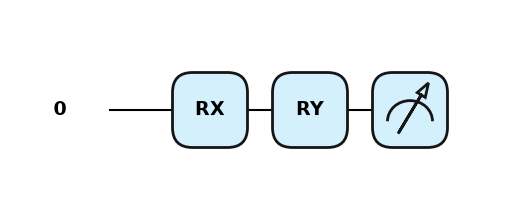

In [7]:
params = np.array([0.54, 0.12])

qp.draw_mpl(circuit,style = "pennylane")(params)

In [8]:
print(circuit(params))

[0.96203663+0.01599429j 0.05779156-0.26625146j]


### Measurements

Then we measure the expectation value
$\langle \psi \mid \sigma_z \mid \psi \rangle$ of the Pauli-Z operator

$$\begin{aligned}
\sigma_z =
\begin{bmatrix} 1 &  0 \\
0 & -1
\end{bmatrix}.
\end{aligned}$$

we find that

$$\langle \psi \mid \sigma_z \mid \psi \rangle
= \langle 0 \mid R_x(\phi_1)^\dagger R_y(\phi_2)^\dagger \sigma_z  R_y(\phi_2) R_x(\phi_1) \mid 0 \rangle
= \cos(\phi_1)\cos(\phi_2).$$

the output lies between $1$ (if
$\left|\psi\right\rangle = \left|0\right\rangle$) and $-1$ (if
$\left|\psi\right\rangle = \left|1\right\rangle$).

In pennylane we need `qp.expval(qp.PauliZ(0))`


In [9]:
##### TODO #####

In [10]:
print(circuit(params))

0.8515405859048367


We've seen how to get the statevector and how to measure the expectation value but there are other possible outcome types we can get with pennylane. 

In practice, on real devices, is not possible to get the full statevector. 

We can measure many times the output qubit according to the number of shots (`@qp.set_shots(shots=100)`) via `qp.counts()` or get the probabilities.

In [11]:
##### TODO #####

print(f"QNode output = {circuit([0.54, 0.12])}")

QNode output = {np.str_('0'): np.int64(90), np.str_('1'): np.int64(10)}


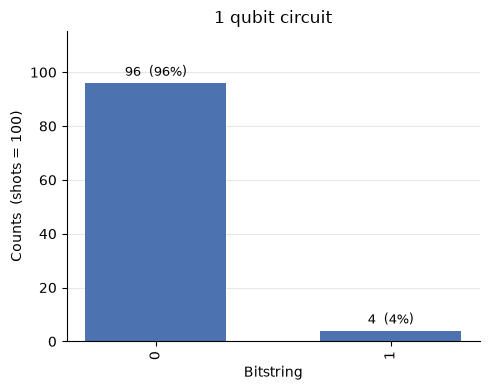

In [12]:
counts=circuit(params)
plot_hist(counts,"1 qubit circuit")

We can also get the probabilities with `qp.probs(wires=range(n))`. If we don't set the shots we get the ideal probabilities.

In [13]:
##### TODO #####

print(f"QNode output = {circuit([0.54, 0.12])}")

QNode output = [0.92 0.08]


Now let's introduce two-qubit gates with the following Bell state preparation circuit: we need a Hadamard gate on the first qubit and a CNOT acting on the two qubits.

In [14]:
dev = qp.device('default.qubit', wires=2)

@qp.set_shots(shots=100)
@qp.qnode(dev)
def circuit():
    ##### TODO #####
    return qp.probs(wires=range(2))

QNode output = [0.48 0.   0.   0.52]


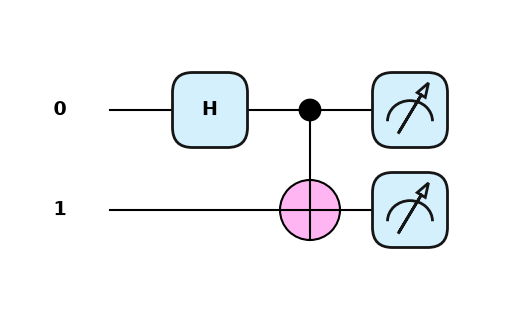

In [15]:
qp.draw_mpl(circuit,style = "pennylane")()
print(f"QNode output = {circuit()}")

Let's just get the counts with `qp.counts()` and visualize the outcomes:

In [17]:
##### TODO #####

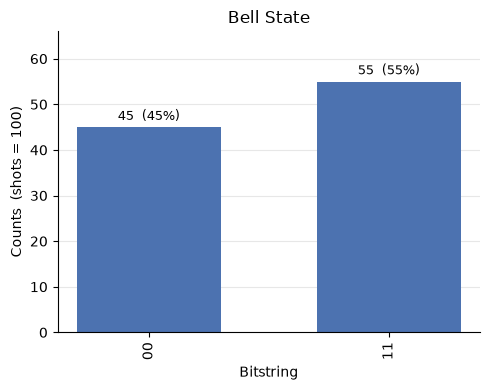

In [18]:
counts=circuit()
plot_hist(counts,"Bell State")

# Let's run our first quantum algorithm

Next notebook!

